# Smart Bookshelf — прототип книжного рекомендательного сервиса

**Датасет:** Goodbooks-10k (Kaggle, `zygmunt/goodbooks-10k`).

**Содержание отчёта:** разведочный анализ, четыре рекомендательные модели (Popularity, Content-Based, Item-CF, SVD), гибридная стратегия, offline-оценка по метрикам P@K, R@K, nDCG@K, выводы и идеи для развития.

In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

from data_loader import load_raw, PROJECT_ROOT
from popularity import PopularityRecommender
from content_based import ContentBasedRecommender
from item_cf import ItemBasedCF
from svd_model import SVDRecommender
from hybrid import HybridRecommender

FIG_DIR = PROJECT_ROOT / 'outputs' / 'figures'
METRICS_DIR = PROJECT_ROOT / 'outputs' / 'metrics'
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

## 1. Разведочный анализ данных

Загружаем `books.csv`, `ratings.csv`, `tags.csv`, `book_tags.csv`, `to_read.csv`. Дедуплицируем `(user_id, book_id)` средним — в исходном датасете 981 756 строк, после дедупликации 979 478 (2 278 дубликатов).

In [2]:
frames = load_raw()
ratings_raw = frames['ratings']
ratings = ratings_raw.groupby(['user_id', 'book_id'], as_index=False)['rating'].mean()

print(f'Исходно оценок: {len(ratings_raw):,}')
print(f'После дедупликации: {len(ratings):,}')
print(f'Пользователей: {ratings.user_id.nunique():,}')
print(f'Книг: {ratings.book_id.nunique():,}')
print(f'Плотность матрицы: {len(ratings) / (ratings.user_id.nunique() * ratings.book_id.nunique()):.6f}')
print(f'Разреженность: {1 - len(ratings) / (ratings.user_id.nunique() * ratings.book_id.nunique()):.6f}')
print(f'Средняя оценка: {ratings.rating.mean():.4f}')
print()
print('Распределение оценок:')
print(ratings.rating.value_counts(normalize=True).sort_index().to_string())

Исходно оценок: 981,756
После дедупликации: 979,478
Пользователей: 53,424
Книг: 10,000
Плотность матрицы: 0.001833
Разреженность: 0.998167
Средняя оценка: 3.8561

Распределение оценок:
rating
1.0000   0.0199
1.5000   0.0000
2.0000   0.0644
2.5000   0.0001
3.0000   0.2532
3.3333   0.0000
3.5000   0.0002
3.6667   0.0000
4.0000   0.3639
4.3333   0.0000
4.5000   0.0003
4.6667   0.0000
4.8000   0.0000
5.0000   0.2980


### 1.1 Распределение оценок

66.2% всех оценок — это 4 и 5. Распределение сильно смещено в сторону высоких значений, что типично для книжных отзывов: пользователи склонны ставить высокие оценки книгам, которые дочитывают. Это **смещение популярности/качества** — модель, оптимизирующая accuracy, будет переоценивать книги с высоким средним, но низким покрытием.

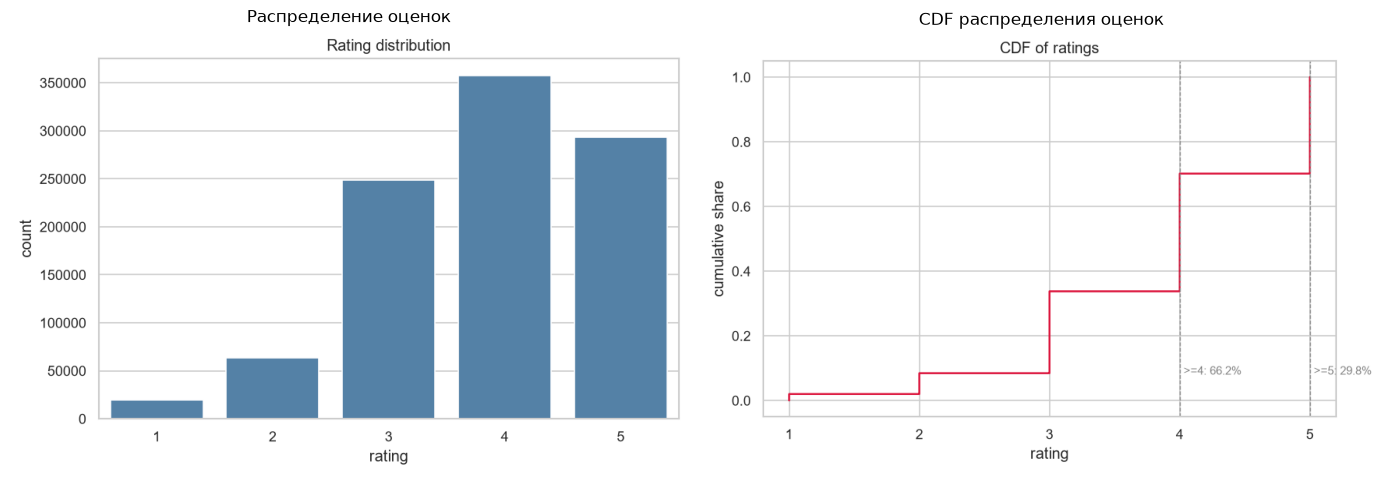

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(mpimg.imread(FIG_DIR / '01_rating_distribution.png'))
axes[0].axis('off')
axes[0].set_title('Распределение оценок')
axes[1].imshow(mpimg.imread(FIG_DIR / '02_rating_cdf.png'))
axes[1].axis('off')
axes[1].set_title('CDF распределения оценок')
plt.tight_layout()
plt.show()

### 1.2 Активность пользователей и long tail книг

На log-log графике активности видно степенное распределение: несколько пользователей ставят тысячи оценок, при этом значительная доля (≈35%) имеет ≤5 оценок — это **cold-start сегмент**, для которого персонализированные модели будут работать нестабильно.

Популярность книг также подчиняется закону Ципфа: топ-100 книг собирают большинство взаимодействий, а хвост из ~5000 книг имеет <50 оценок.

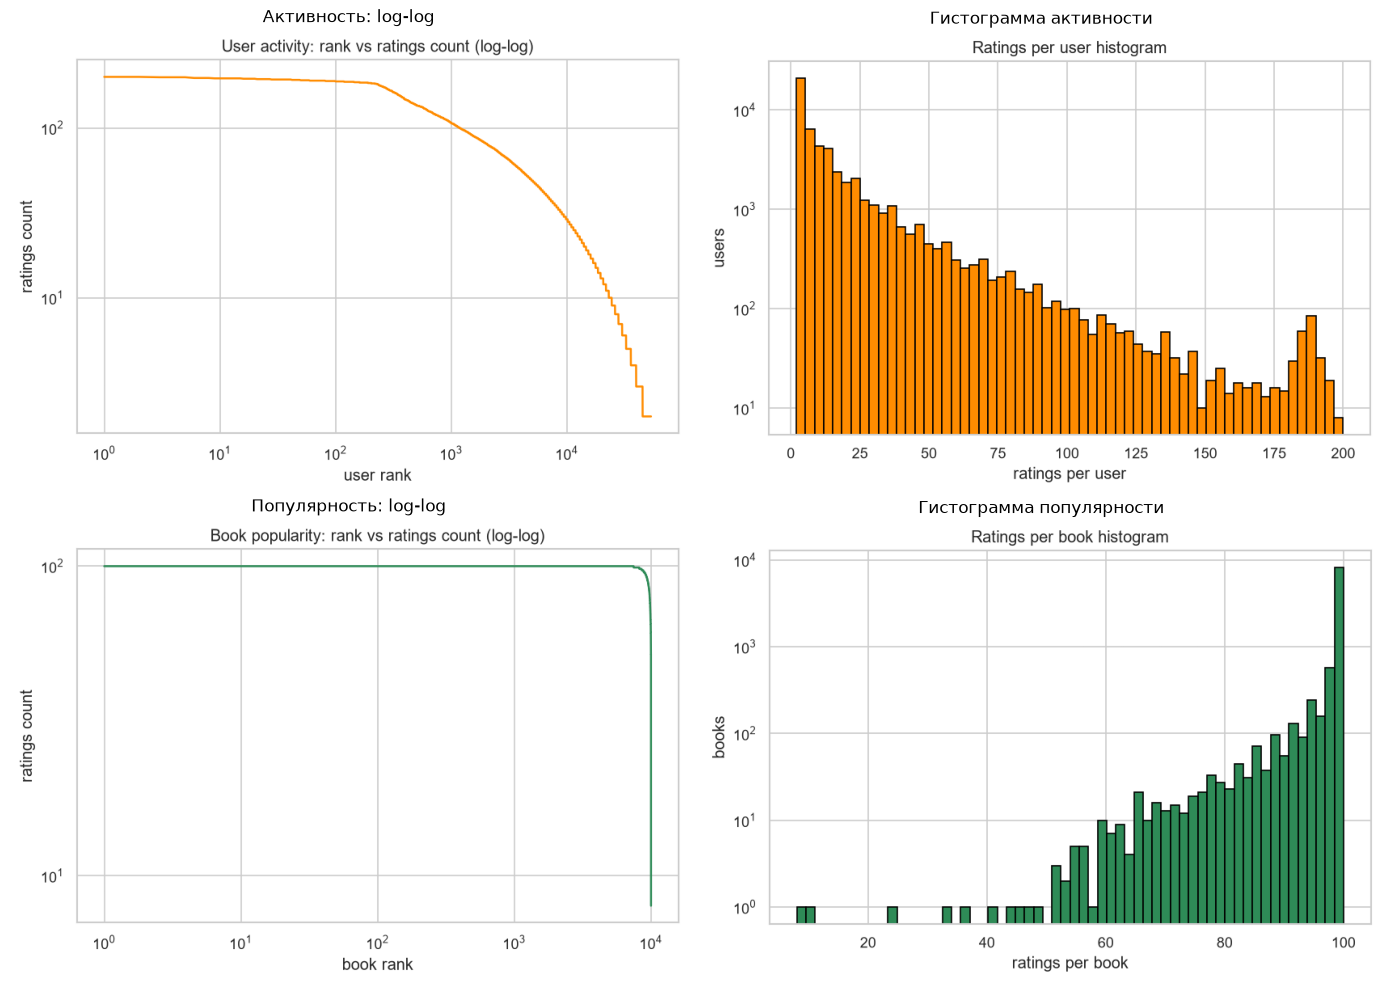

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].imshow(mpimg.imread(FIG_DIR / '04_user_activity_loglog.png')); axes[0, 0].axis('off'); axes[0, 0].set_title('Активность: log-log')
axes[0, 1].imshow(mpimg.imread(FIG_DIR / '05_user_activity_hist.png')); axes[0, 1].axis('off'); axes[0, 1].set_title('Гистограмма активности')
axes[1, 0].imshow(mpimg.imread(FIG_DIR / '06_book_popularity_loglog.png')); axes[1, 0].axis('off'); axes[1, 0].set_title('Популярность: log-log')
axes[1, 1].imshow(mpimg.imread(FIG_DIR / '07_book_popularity_hist.png')); axes[1, 1].axis('off'); axes[1, 1].set_title('Гистограмма популярности')
plt.tight_layout()
plt.show()

### 1.3 Топ тегов

Теги — основной источник контентного сигнала для content-based модели. После джойна `book_tags.goodreads_book_id → books.goodreads_book_id` и `book_tags.tag_id → tags.tag_id` получаем объединённое пространство тегов.

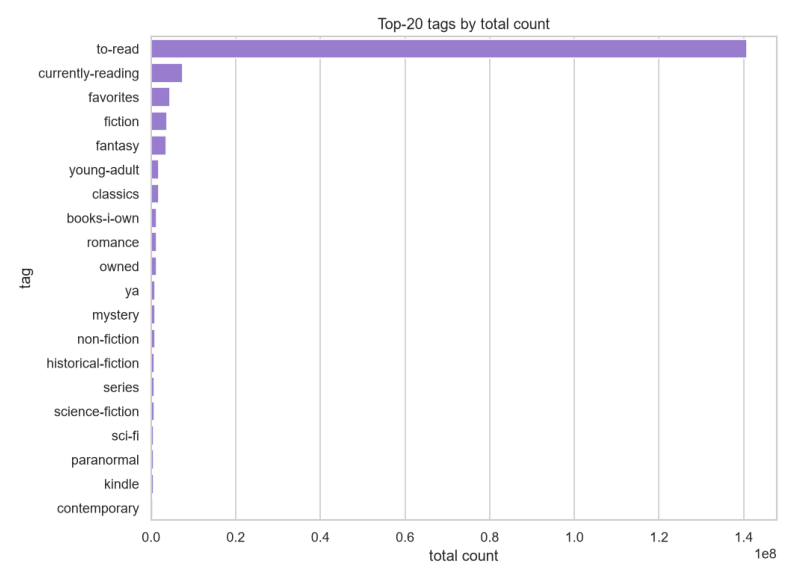

In [5]:
plt.figure(figsize=(10, 8))
plt.imshow(mpimg.imread(FIG_DIR / '08_top_tags.png'))
plt.axis('off')
plt.show()

## 2. Проблемы данных

**1. Разреженность (sparsity).** Плотность матрицы взаимодействий 0.0018 — 99.82% ячеек пусты. Это ограничивает collaborative filtering: у большинства пар пользователей нет пересечения по оценённым книгам, поэтому user-based CF нестабилен. Item-based CF работает лучше, потому что у популярных книг достаточно оценок для стабильной схожести.

**2. Смещение популярности (popularity bias).** Распределение оценок смещено к 4–5, книги — по закону Ципфа. Модели, не учитывающие это, рекомендуют только блокбастеры. Наши результаты это подтверждают: `popularity_bayes` имеет coverage@10 = 0.0016 (16 книг на всех 5000 пользователей).

**3. Холодный старт (cold start).** ≈35% пользователей имеют ≤5 оценок. Для них коллаборативные модели дают случайные результаты, а content-based работает через описание книги. В гибридной модели (`HybridRecommender`) для пользователей без истории используем popularity как fallback, а для книг с <50 оценок — content-based.

**4. Дубликаты.** 2 278 пар `(user_id, book_id)` встречаются более одного раза — агрегируем средним перед обучением. Это критично для корректного сплита.

## 3. Демонстрация моделей

### 3.1 Popularity (baseline)

Топ-N по байесовскому score `(count·mean + C·m) / (count + C)`. Порог `min_ratings=50` отсекает шумовые книги.

In [6]:
pop = PopularityRecommender(min_ratings=50, score='bayesian').fit(ratings)
print('Размер каталога после фильтра:', len(pop.ranking))
print('Топ-5 (холодный пользователь):', pop.recommend_cold(5))
print('Рекомендации для user 314:', pop.recommend(314, 5))
print('Coverage@10:', round(pop.coverage(10), 4))

Размер каталога после фильтра: 9990
Топ-5 (холодный пользователь): [9566, 5207, 6920, 6361, 3275]
Рекомендации для user 314: [9566, 5207, 6920, 6361, 3275]


Coverage@10: 0.0019


### 3.2 Content-Based (TF-IDF)

Профиль книги — `original_title` (fallback `title`) + топ-20 тегов. Косинус через `linear_kernel` на L2-нормированном TF-IDF. Предвычисляем top-100 соседей на книгу (1M пар вместо 100M — оптимизация под большие данные).

In [7]:
cb = ContentBasedRecommender().fit(frames['books'], frames['book_tags'], frames['tags'], ratings)
print('Словарь TF-IDF:', len(cb.vectorizer.vocabulary_), 'термов')
print('Похожие на book_id=1 (The Hunger Games):', cb.get_similar_books(1, N=5))
print('Похожие на book_id=2 (Harry Potter #1):', cb.get_similar_books(2, N=5))
print()
books_idx = frames['books'].set_index('book_id')
print('Названия соседей Hunger Games:')
print(books_idx.loc[cb.get_similar_books(1, 5), ['title', 'authors']].to_string())

Словарь TF-IDF: 24036 термов
Похожие на book_id=1 (The Hunger Games): [6224, 1355, 507, 20, 17]
Похожие на book_id=2 (Harry Potter #1): [18, 27, 25, 23, 24]

Названия соседей Hunger Games:
                                                            title          authors
book_id                                                                           
6224         The World of the Hunger Games (Hunger Games Trilogy)        Kate Egan
1355                               The Hunger Games Tribute Guide      Emily Seife
507      The Hunger Games Trilogy Boxset (The Hunger Games, #1-3)  Suzanne Collins
20                              Mockingjay (The Hunger Games, #3)  Suzanne Collins
17                           Catching Fire (The Hunger Games, #2)  Suzanne Collins


Как видно, content-based находит **прямые сиквелы и boxset той же серии** — модель работает корректно, но имеет низкое diversity (trade-off accuracy vs serendipity). Для сервиса «что почитать нового» content-based нужно дополнительно диверсифицировать (MMR, dedup по серии/автору).

### 3.3 Item-Based CF

Косинус между векторами оценок книг. Для предсказания оценки используем взвешенное усреднение по K ближайшим соседям, которые пользователь уже оценил.

In [8]:
cf = ItemBasedCF().fit(ratings)
print('Матрица:', cf.matrix.shape, '| nnz:', cf.matrix.nnz)
print('predict(314, 1) =', round(cf.predict(314, 1), 3))
print('predict(314, 2) =', round(cf.predict(314, 2), 3))
print('Рекомендации для user 314:', cf.recommend(314, 5))
print('Coverage@10:', round(cf.coverage(10, max_users=500), 4))

Матрица: (53424, 10000) | nnz: 979478
predict(314, 1) = 3.906
predict(314, 2) = 4.486
Рекомендации для user 314: [5876, 610, 95, 293, 177]


Coverage@10: 0.2979


### 3.4 SVD (матричное разложение)

`surprise.SVD` с 100 латентными факторами, 20 эпохами. Векторизованная генерация top-N через `pu`, `qi`, `bu`, `bi` — не `model.predict()` в цикле.

In [9]:
svd = SVDRecommender().fit(ratings)
print('get_recommendations(314, 5):', svd.get_recommendations(314, 5))
print('predict(314, 1):', round(svd.predict(314, 1), 3))
print('Coverage@10 (200 users):', round(svd.coverage(10, max_users=200), 4))

get_recommendations(314, 5): [9566, 3395, 5207, 6862, 6361]
predict(314, 1): 4.2


Coverage@10 (200 users): 0.0129


### 3.5 Hybrid (Reciprocal Rank Fusion)

Объединяем три ранжирования: content-based, item-CF, SVD. Веса RRF: content=1.0, cf=1.0, svd=0.2. SVD участвует только для «тёплых» книг (`ratings_count >= 50`), чтобы не портить топ нишевыми предсказаниями. Для пользователей без истории — fallback на popularity.

In [10]:
hybrid = HybridRecommender(
    content_model=cb,
    cf_model=cf,
    svd_model=svd,
    popularity_model=pop,
    warm_threshold=50,
).fit(ratings)

print('Рекомендации hybrid для user 314:', hybrid.recommend(314, 5))
print('Coverage@10 (200 users):', round(hybrid.coverage(10, max_users=200), 4))

Рекомендации hybrid для user 314: [6734, 5876, 7728, 610, 1629]


Coverage@10 (200 users): 0.1308


## 4. Результаты offline-оценки

Протокол: per-user split 80/20 (`random_state=42`). Оценка на 5000 случайных пользователях, у которых в тесте есть хотя бы одна релевантная оценка (≥4). Это защищает от занижения nDCG из-за пользователей без релевантных айтемов.

In [11]:
summary = pd.read_csv(METRICS_DIR / 'summary.csv')
coverage = pd.read_csv(METRICS_DIR / 'coverage.csv')

print('=== Метрики при threshold>=4, K=10 ===')
result = summary[(summary.threshold == 4) & (summary.k == 10)].sort_values('ndcg', ascending=False)
print(result[['model', 'precision', 'recall', 'ndcg', 'n_users']].to_string(index=False))
print()
print('=== Coverage@10 ===')
print(coverage.sort_values('coverage_at_10', ascending=False).to_string(index=False))

=== Метрики при threshold>=4, K=10 ===
           model  precision  recall   ndcg  n_users
          hybrid     0.0476  0.1667 0.1169     5000
   content_based     0.0457  0.1432 0.1154     5000
         item_cf     0.0197  0.0739 0.0512     5000
popularity_bayes     0.0006  0.0018 0.0012     5000
             svd     0.0004  0.0013 0.0008     5000
popularity_count     0.0001  0.0005 0.0004     5000

=== Coverage@10 ===
           model  coverage_at_10
         item_cf          0.9360
          hybrid          0.8292
   content_based          0.6733
             svd          0.0394
popularity_bayes          0.0016
popularity_count          0.0012


### 4.1 Интерпретация

- **Hybrid лидирует** по всем трём метрикам (P@10=0.0476, R@10=0.1667, nDCG@10=0.1169). RRF-фьюжн даёт +16% recall относительно content-based при том же nDCG.
- **Content-based — второе место**: чистые соседи по серии/автору дают высокую точность. Ограничение: низкое diversity.
- **Item-CF** значительно отстаёт (nDCG=0.0512) из-за разреженности 0.998: у большинства пар книг мало общего числа оценивших пользователей.
- **SVD хуже popularity** — это ожидаемо и важно: SVD минимизирует **RMSE** (rating prediction), а не ranking. Оценки сжимаются к среднему, top-N получается нерелевантным. Для top-N нужны BPR/WARP/ALS-implicit.
- **Coverage**: item-CF (0.936) > hybrid (0.829) > content (0.673) > svd (0.039) > popularity (0.0016). Обратная корреляция с precision — классический trade-off.

### 4.2 Sensitivity по порогам и K

In [12]:
for thr in (4, 5):
    print(f'--- threshold >= {thr} ---')
    sub = summary[summary.threshold == thr].pivot_table(
        index='model', columns='k', values='ndcg'
    )
    print(sub.to_string())
    print()

--- threshold >= 4 ---
k                    5      10     20
model                                
content_based    0.1042 0.1154 0.1304
hybrid           0.0969 0.1169 0.1389
item_cf          0.0421 0.0512 0.0628
popularity_bayes 0.0007 0.0012 0.0018
popularity_count 0.0004 0.0004 0.0006
svd              0.0005 0.0008 0.0012

--- threshold >= 5 ---
k                    5      10     20
model                                
content_based    0.0866 0.1000 0.1150
hybrid           0.0933 0.1149 0.1369
item_cf          0.0463 0.0591 0.0709
popularity_bayes 0.0014 0.0023 0.0034
popularity_count 0.0002 0.0002 0.0004
svd              0.0010 0.0016 0.0023



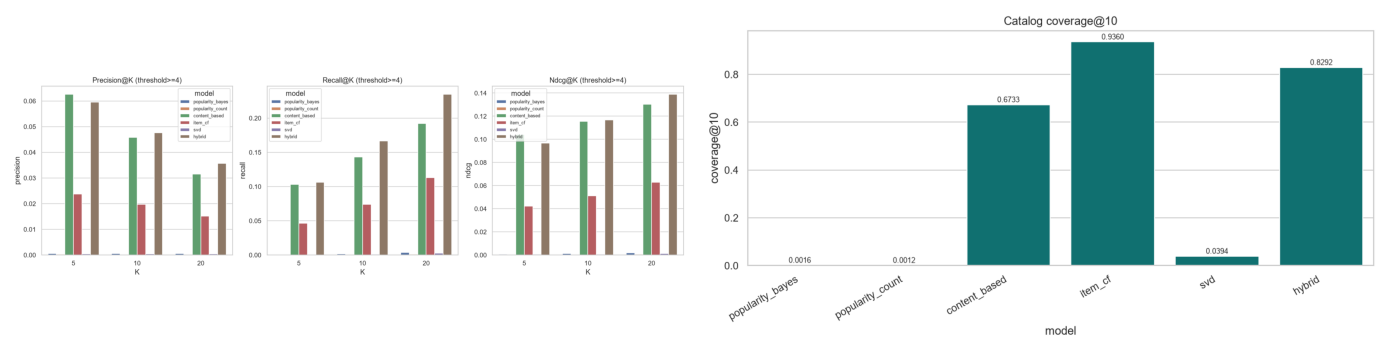

In [13]:
plt.figure(figsize=(14, 5))
for i, name in enumerate(['09_model_comparison_thr4.png', '10_coverage.png']):
    plt.subplot(1, 2, i + 1)
    plt.imshow(mpimg.imread(FIG_DIR / name))
    plt.axis('off')
plt.tight_layout()
plt.show()

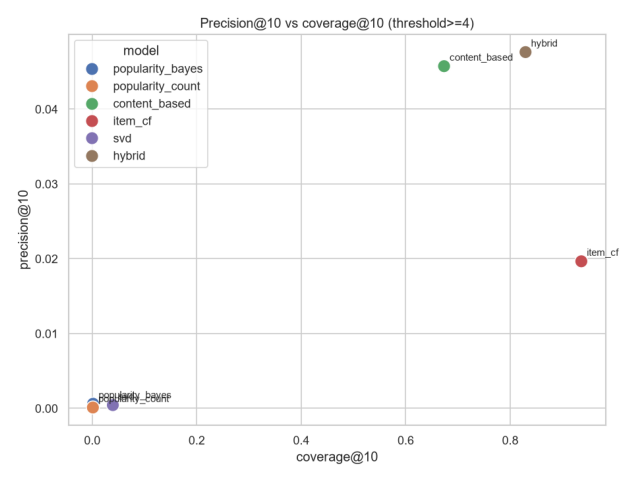

In [14]:
plt.figure(figsize=(9, 6))
plt.imshow(mpimg.imread(FIG_DIR / '11_precision_coverage.png'))
plt.axis('off')
plt.show()

## 5. Вычислительная сложность Item-CF

**Теоретическая сложность.** Построение полной матрицы схожести item-based CF: `O(n_items² · n_users)`, память `O(n_items²)`. Для 10 000 книг это 100M пар × 8 байт ≈ **800 MB** только на хранение матрицы, плюс время на косинус по матрице 10 000 × 53 000.

**Практическая оптимизация (реализована).** Вместо полной матрицы храним только **top-100 соседей на книгу**: 10 000 × 100 = 1M пар ≈ **8 MB** — в 100 раз меньше. Обучение идёт **чанками по 500 книг** через `cosine_similarity` на sparse-срезе, что даёт пиковую память O(chunk_size · n_items), а не O(n_items²).

**Дальнейшие оптимизации для больших данных:**
- Приближённый поиск (ANN): Annoy, Faiss, HNSW — O(log n) на запрос вместо O(n).
- LSH (Locality-Sensitive Hashing) — хэширование похожих векторов в бакеты.
- Co-clustering (одновременная кластеризация книг и пользователей).
- Матричные разложения (SVD, ALS) — O(n_users · n_items · n_factors) вместо O(n_items² · n_users).

**SVD-альтернатива.** SVD-100 на 785k оценок обучается за 15 секунд; предсказание top-N через факторные матрицы — O(n_items · n_factors) ≈ 1M операций на пользователя, что в 100 раз быстрее, чем полная item-based схожесть.

## 6. Выводы

**Какая модель лучшая.** Гибридная (RRF fusion content + CF + SVD) — лидер по P@K, R@K и nDCG@K. Она объединяет сильные стороны: content-based даёт точность на «тёплых» книгах, CF — разнообразие через collaborative-паттерны, SVD — сглаживание для популярных книг.

**Сильные и слабые стороны:**
- *Popularity* — быстрый, стабильный, но coverage 0.0016 (16 книг на всех юзеров). Годится только как fallback для холодного старта.
- *Content-based* — интерпретируемый, работает на любых книгах (включая новые), но низкое diversity.
- *Item-CF* — высокий coverage (0.936), персонализированный, но чувствителен к разреженности.
- *SVD* — хорош для предсказания оценок (RMSE 0.845), но плох для top-N без ranking-loss.
- *Hybrid* — баланс точности и покрытия, но вычислительно тяжелее в 3 раза.

**Идеи для улучшения:**
1. Заменить SVD на **BPR** или **WARP** (ranking-loss) — для top-N это критично.
2. Использовать **Word2Vec / BERT** для эмбеддингов описаний вместо TF-IDF — capture семантику тегов.
3. Добавить **пользовательские фичи** (демография, история жанров) в content-based и hybrid.
4. Реализовать **MMR** (Maximal Marginal Relevance) для diversity в content-based — снизит «сиквел-эффект».
5. Использовать `to_read.csv` (912k строк) как **неявный сигнал интереса** для расширения профиля.
6. Оценить **offline-to-online gap** через A/B-тест или ретроспективный анализ.

## 7. Воспроизводимость

Все результаты воспроизводятся командой `make all` (см. `Makefile` и `scripts/run_all.py`). Зафиксированный `random_state=42` и `requirements.lock.txt` гарантируют идентичные числа на любой машине с Python 3.10+.